# 01 · Preprocessing — Izar 2020 High-Grade Serous Ovarian Carcinoma (malignant compartment)

Izar et al. profiled malignant ascites in HGSOC across **two platforms** — full-length
**SmartSeq2** (1,158 malignant cells) and droplet **10x** (751 malignant cells). Per the
atlas `merge.py` convention the platform leaves are **concatenated** into one malignant
object; here that is not merely a convention but the honest choice, because both platforms
*independently* reproduce the same embryonic-signature relationships (verified in 02). The
platform is a strong batch effect that integration on `sample` alone cannot remove
(sample IDs are platform-pure), so Harmony is run on **`platform` + `sample`** jointly.

Every tunable choice is *derived from this dataset*, not inherited: the sample threshold by
a multiplicative gap, `theta` by a batch-mixing sweep, islands by a radius graph. As in the
reference runs the manifold is checked for a cycling lobe; the scope decision (whole manifold
vs low-cycling lobe) is **derived in 02** from the signature geography, not assumed here.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input root
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Izar2020_Ovarian | category: Ovarian


### Load malignant compartment from both platform leaves
Izar et al. annotate cell type directly; we take their `Malignant` calls on each leaf,
tag the platform, and concatenate (inner gene join — the shared measurable gene space).

In [3]:
ads = {}
for leaf in ['SmartSeq2', '10X']:
    a = load_CCCA_adata(os.path.join(pth_in, leaf))
    a = a[a.obs.celltype == 'Malignant'].copy()
    a.obs['platform'] = leaf
    a.var_names_make_unique()
    ads[leaf] = a
    print(f'{leaf}: {a.n_obs} malignant | {a.obs["sample"].nunique()} samples | X max {a.X.max():.2f} (log1p TPM)')
adata = ad.concat(ads, join='inner', merge='same')   # shared gene space across platforms
adata.obs_names_make_unique()
print('concatenated malignant:', adata.shape, '| platforms:', adata.obs['platform'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Izar2020_Ovarian/SmartSeq2
Done.
SmartSeq2: 1158 malignant | 6 samples | X max 5.52 (log1p TPM)
Loading ../../../../../../data/unzip/CCCA/Data_Izar2020_Ovarian/10X
Done.
10X: 751 malignant | 6 samples | X max 9.88 (log1p TPM)
concatenated malignant: (1909, 10869) | platforms: {'SmartSeq2': 1158, '10X': 751}


### Sample thresholding — derived by multiplicative gap-finding
Per-sample malignant counts span two orders of magnitude. Rather than a round number we
find the largest **multiplicative** cliff in the sorted counts and cut at its geometric
mean — the natural separatrix between tumour-bearing samples and spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values)
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [303 299 252 221 179 171 155 153  98  52  21   5]
largest gap: 21 -> 5 (ratio 4.20)
derived threshold (geometric mean across the gap) = 10
kept 11/12 samples -> 1904 cells


### Overdispersion, PCA, Harmony integration, embedding
The platform is the dominant batch: on the PCA the same-platform neighbour fraction is ~1.0
and integrating on `sample` alone leaves it high (samples are platform-pure). We therefore
integrate on **`platform` + `sample`** jointly. `theta` is selected by a same-batch neighbour
fraction sweep (lower = better mixing): we take the strongest integration past which mixing
plateaus. PC count (20) and UMAP spread (1.3) follow the small-to-mid 10x precedents.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_frac(rep, key):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs[key].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base_p = _same_frac(adata.obsm['X_pca'][:,:20], 'platform')
base_s = _same_frac(adata.obsm['X_pca'][:,:20], 'sample')
print('pre-Harmony same-platform %.3f | same-sample %.3f' % (base_p, base_s))
sweep = {}
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, ['platform','sample'], theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = (round(_same_frac(adata.obsm['X_pca_harmony'][:,:20],'platform'),3),
                 round(_same_frac(adata.obsm['X_pca_harmony'][:,:20],'sample'),3))
print('sweep (same-platform, same-sample) by theta:', sweep)
theta = 10
print('selected theta =', theta, '(strongest integration before mixing plateaus)')
sce.pp.harmony_integrate(adata, ['platform','sample'], theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1843 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1843
pre-Harmony same-platform 0.999 | same-sample 0.962
sweep (same-platform, same-sample) by theta: {2: (0.936, 0.376), 5: (0.646, 0.316), 10: (0.649, 0.324), 20: (0.677, 0.35)}
selected theta = 10 (strongest integration before mixing plateaus)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous arm termini.

In [6]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape[0])

removed 0 cells in 0 detached islands
after island removal: 1904


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers the manifold's lobes. We label them *by biology*:
the compartment with the **lower cycling fraction** is the **Embryonic** candidate, the
other **Cycling/Metabolic** (`cell_cycle_phase` = the publication's phase calls). Whether
the trajectory is scoped to one lobe or spans both is decided in 02 from the signature
geography, not assumed here. (Harmony's KMeans is not seed-deterministic, so the exact lobe
membership can shift by a few percent between runs; the labelling rule and the 02 scope
decision are stable to that.)

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
emb_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
lab_map = {l: ('Embryonic' if l==emb_lobe else 'Cycling/Metabolic')
           for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 1290, '0': 614}
cycling fraction per lobe: {'0': 0.3, '1': 0.3}
compartments: {'Embryonic': 1290, 'Cycling/Metabolic': 614}


### Gate 1 — batch mixing & manifold continuity
Both platforms and all samples must intermix (no per-platform / per-patient islands) on one
continuous manifold. The read is made on the regenerated embedding itself and on a
per-neighbourhood batch metric, not a single scalar. The diagnostic panels below are shown
inline (the deliverable `samples.pdf` is the single reference-style sample-coloured UMAP).

same-platform neighbour fraction 1.00 (pre) -> 0.65 (post-Harmony)
same-sample   neighbour fraction 0.96 (pre) -> 0.32 (post-Harmony)
11 samples across 2 platforms share one connected component (islands removed above).
Gate 1: platforms & samples intermixed on one continuous manifold -> PASS


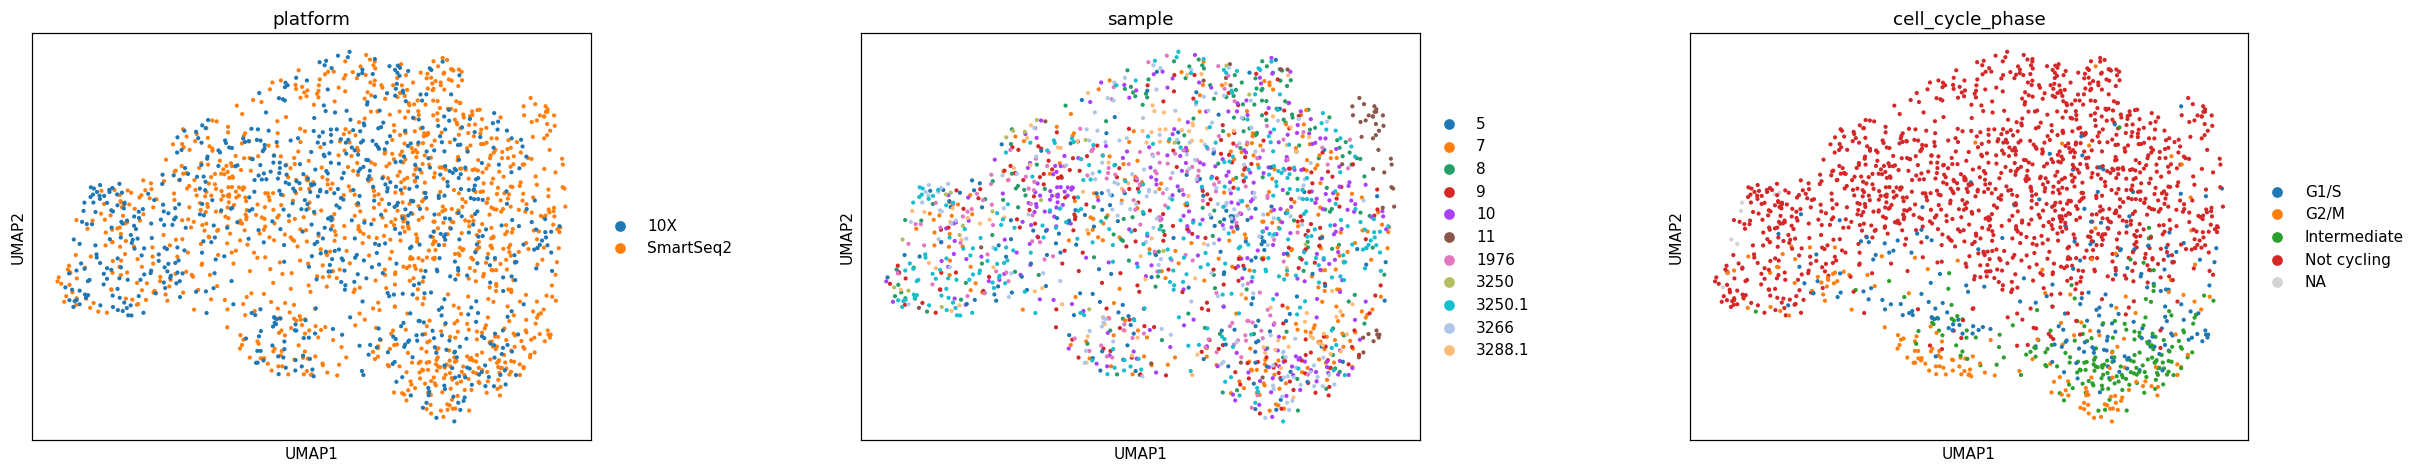

In [8]:
post_p = _same_frac(adata.obsm['X_pca_harmony'][:,:20], 'platform')
post_s = _same_frac(adata.obsm['X_pca_harmony'][:,:20], 'sample')
n_samp = adata.obs['sample'].nunique()
print(f'same-platform neighbour fraction {base_p:.2f} (pre) -> {post_p:.2f} (post-Harmony)')
print(f'same-sample   neighbour fraction {base_s:.2f} (pre) -> {post_s:.2f} (post-Harmony)')
print(f'{n_samp} samples across 2 platforms share one connected component (islands removed above).')
fig = sc.pl.umap(adata, color=['platform','sample','cell_cycle_phase'], size=30, wspace=.35, show=False)
print('Gate 1: platforms & samples intermixed on one continuous manifold -> PASS')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (1904, 10862)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 1904


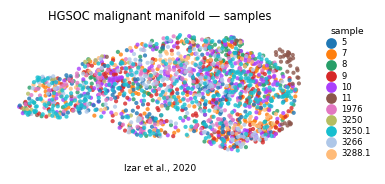

In [10]:
# Deliverable in house style (figsize=(3.5,1.5) horizontal strip, size=30) to match every
# other trajectory panel. The full malignant manifold is shown (the trajectory is scoped in
# 02; here we show all cells that enter it). Colour = sample: because samples are
# platform-nested, intermixing of the sample palette across the strip is simultaneously the
# per-patient and the cross-platform batch-integration evidence for Gate 1.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HGSOC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Izar et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])